In [29]:
import geopandas
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point

# Load zip codes
ZIPS = geopandas.read_file("https://data.wprdc.org/dataset/1a5135de-cabe-4e23-b5e4-b2b8dd733817/resource/ec228c0e-6b1e-4f44-a335-df05546d52ea/download/alcogisallegheny-county-zip-code-boundaries.zip")

# Load neighborhoods and use zip codes to convert
NEIGHBORHOODS = geopandas.read_file("https://data.wprdc.org/dataset/e672f13d-71c4-4a66-8f38-710e75ed80a4/resource/c5a93a8e-03d7-4eb3-91a8-c6b7db0fa261/download/pittsburghpaneighborhoods-.zip").to_crs(ZIPS.crs)

def get_neighborhood(row):
    # Create a shapely point for the latitude and longitude
    pt = Point(row["Longitude"], row["Latitude"])
    ptg = geopandas.GeoDataFrame(geometry=[pt], crs="EPSG:4326").to_crs(NEIGHBORHOODS.crs)
    # Loop through the neighborhoods
    for _idx, neighborhood in NEIGHBORHOODS.iterrows():
        # Check if this neighborhood contains the point
        if neighborhood["geometry"].contains(ptg.geometry.iloc[0]):
            # Return the name of the neighborhood
            return neighborhood["hood"]
    # Wasn't contained in the neighborhood
    return None

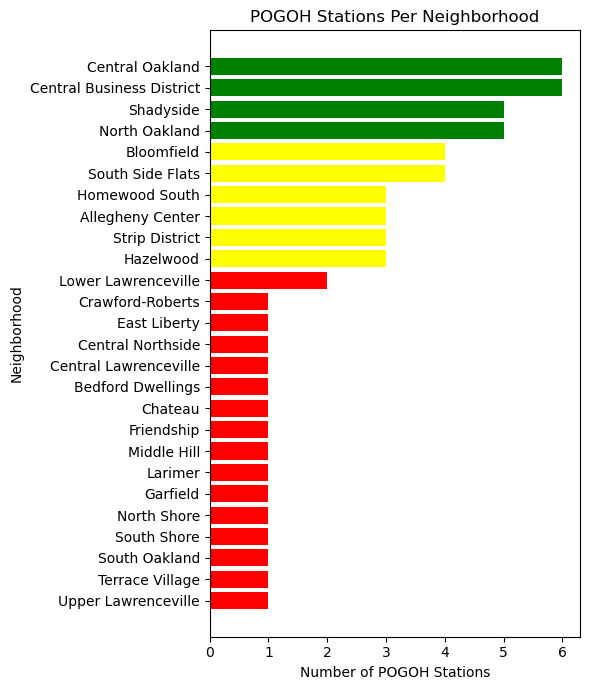

In [41]:
racks = pd.read_csv("pogohstation.csv")

racks["neighborhood"] = racks.apply(get_neighborhood, axis=1)

racks_by_neighborhood = racks.groupby("neighborhood").size().reset_index(name="num_racks").sort_values(by="num_racks", ascending=False)

plt.figure(figsize=(6,7))
plt.barh(racks_by_neighborhood["neighborhood"], racks_by_neighborhood["num_racks"], color=color)
plt.xlabel("Number of POGOH Stations")
plt.ylabel("Neighborhood")
plt.title("POGOH Stations Per Neighborhood")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()